# Paso 6 — Caracterización de clases latentes por factores del EFA

**Objetivo:** Describir cada clase latente en términos de las variables latentes identificadas por el EFA.

**Inputs:**
- `dataset_lca_clases.csv` — clases asignadas a cada estudiante
- `efa_cargas_factoriales.csv` — cargas factoriales por ítem
- `dataset_filtrado.csv` — valores originales de los ítems

**Output:**
- `tabla_perfiles_clases.csv` — tabla de perfiles para el artículo
- `tabla_contexto_clases.csv` — distribución de contexto por clase

## 0. Configuración

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Nombres interpretativos de cada factor (basados en el codebook PISA 2022)
# Formato: "codigo_factor" : "nombre_interpretativo"
NOMBRES_FACTORES = {
    # Bloque estudiante
    "F1_estudiante" : "Actividades creativas fuera de la escuela",
    "F2_estudiante" : "Capital cultural y recursos del hogar",
    "F3_estudiante" : "Exposición a violencia y acoso escolar",
    "F4_estudiante" : "Estrategias de aprendizaje matemático",
    "F5_estudiante" : "Expectativas educativas y aspiraciones",
    "F6_estudiante" : "Recursos digitales del hogar",
    "F7_estudiante" : "Sentido de pertenencia escolar",
    "F8_estudiante" : "Participación en clases de matemáticas",
    "F9_estudiante" : "Ansiedad matemática",
    # Bloque escuela_a
    "F1_escuela_a"  : "Uso de tecnología digital en la escuela",
    "F2_escuela_a"  : "Uso de evaluaciones estandarizadas",
    "F3_escuela_a"  : "Escasez de recursos educativos",
    "F4_escuela_a"  : "Escasez de personal docente",
    "F5_escuela_a"  : "Autonomía de gestión escolar",
    "F6_escuela_a"  : "Actitudes inclusivas del director",
    # Bloque escuela_b
    "F1_escuela_b"  : "Retroalimentación docente formativa",
    "F2_escuela_b"  : "Liderazgo instruccional del director",
    "F3_escuela_b"  : "Colaboración entre docentes",
    "F4_escuela_b"  : "Disponibilidad de TIC en el aula",
    "F5_escuela_b"  : "Frecuencia de uso de recursos digitales",
    "F6_escuela_b"  : "Comunicación escuela-familia",
    # Bloque escuela_c
    "F1_escuela_c"  : "Tipo de gestión y financiamiento escolar",
    "F2_escuela_c"  : "Prácticas pedagógicas post-COVID",
    "F3_escuela_c"  : "Adaptaciones escolares durante COVID-19",
    "F4_escuela_c"  : "Programas de bienestar estudiantil",
    "F5_escuela_c"  : "Obstáculos para el aprendizaje matemático",
    "F6_escuela_c"  : "Uso pedagógico avanzado de TIC",
    # Bloque finanzas
    "F1_finanzas"   : "Comprensión de conceptos financieros básicos",
    "F2_finanzas"   : "Aplicación de conocimiento financiero",
    "F3_finanzas"   : "Toma de decisiones financieras en riesgo",
    "F4_finanzas"   : "Gestión del dinero y ahorro personal",
    "F5_finanzas"   : "Comprensión de productos financieros complejos",
    "F6_finanzas"   : "Planificación financiera a largo plazo",
    "F7_finanzas"   : "Experiencias financieras en el hogar",
    "F8_finanzas"   : "Acceso y uso de servicios financieros",
    # Bloque otros (solo los sustantivos)
    "F2_otros"      : "Trayectoria y nivel educativo del estudiante",
    "F5_otros"      : "Tamaño del grupo-clase",
}

# Factores a DESCARTAR (variables de diseño, no sustantivas)
FACTORES_DESCARTAR = ["F1_otros", "F3_otros", "F4_otros"]

print(f"Factores a interpretar : {len(NOMBRES_FACTORES)}")
print(f"Factores descartados   : {len(FACTORES_DESCARTAR)}")

Factores a interpretar : 37
Factores descartados   : 3


## 1. Cargar datos

In [3]:
df_lca     = pd.read_csv("/workspace/data/ouputs/dataset_lca_clases.csv", low_memory=False)
df_cargas  = pd.read_csv("/workspace/data/ouputs/efa_cargas_factoriales.csv", index_col=0)
df_filtrado = pd.read_csv("/workspace/data/ouputs/dataset_filtrado.csv", low_memory=False)
df_raw     = pd.read_csv("/workspace/data/collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv", low_memory=False)

# "/workspace/data/ouputs/dataset_irt_items_finales.csv"

print(f"LCA clases  : {df_lca.shape}")
print(f"Cargas EFA  : {df_cargas.shape}")
print(f"Filtrado    : {df_filtrado.shape}")
print(f"Raw         : {df_raw.shape}")

N_CLASES = df_lca["clase_lca"].nunique()
print(f"\nNúmero de clases: {N_CLASES}")

LCA clases  : (6968, 161)
Cargas EFA  : (591, 44)
Filtrado    : (6968, 592)
Raw         : (6968, 7147)

Número de clases: 7


## 2. Calcular puntuación de cada estudiante en cada factor

Para cada factor: promedio ponderado por carga de los ítems que lo componen.
Luego estandarizar (z-score) para que todos los factores sean comparables.

In [4]:
# Columnas de factores disponibles en df_cargas
cols_factores = [c for c in df_cargas.columns
                 if c.startswith("F") and c in NOMBRES_FACTORES
                 and c not in FACTORES_DESCARTAR]

print(f"Factores a procesar: {len(cols_factores)}")

df_scores = pd.DataFrame(index=df_filtrado.index)

for factor in cols_factores:
    if factor not in df_cargas.columns:
        continue

    # Ítems que cargan en este factor (carga absoluta >= 0.30)
    cargas_factor = df_cargas[factor].dropna()
    items_factor  = cargas_factor[cargas_factor.abs() >= 0.30].index.tolist()

    # Solo ítems que existen en el dataset filtrado
    items_disponibles = [i for i in items_factor if i in df_filtrado.columns]

    if len(items_disponibles) == 0:
        continue

    # Puntuación = promedio ponderado por carga absoluta
    pesos = cargas_factor[items_disponibles].abs()
    datos = df_filtrado[items_disponibles]

    # Imputar missing con mediana antes de calcular score
    datos_imp = datos.apply(lambda col: col.fillna(col.median()))

    score = (datos_imp * pesos).sum(axis=1) / pesos.sum()
    df_scores[factor] = score

# Estandarizar todos los scores (z-score)
df_scores_z = (df_scores - df_scores.mean()) / df_scores.std()

print(f"Scores calculados para {df_scores_z.shape[1]} factores")
print(f"Shape: {df_scores_z.shape}")

Factores a procesar: 37
Scores calculados para 37 factores
Shape: (6968, 37)


## 3. Calcular perfil promedio por clase latente

In [5]:
# Agregar clase al dataframe de scores
df_scores_z["clase_lca"]        = df_lca["clase_lca"].values
df_scores_z["score_rendimiento"] = df_lca["score_rendimiento"].values

# Promedio de cada factor por clase
factores_cols = [c for c in df_scores_z.columns
                 if c.startswith("F") and c in NOMBRES_FACTORES]

df_perfil = df_scores_z.groupby("clase_lca")[factores_cols].mean().round(3)

# Ordenar clases por rendimiento (de mayor a menor)
orden_rendimiento = (
    df_scores_z.groupby("clase_lca")["score_rendimiento"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)
df_perfil = df_perfil.loc[orden_rendimiento]

# Renombrar columnas con nombres interpretativos
df_perfil_named = df_perfil.rename(columns=NOMBRES_FACTORES)

# Renombrar filas con etiqueta de rendimiento
etiquetas_clase = {
    orden_rendimiento[2]: "Clase 1 — Rendimiento destacado",
    orden_rendimiento[6]: "Clase 2 — Rendimiento alto",
    orden_rendimiento[3]: "Clase 3 — Rendimiento medio-alto A",
    orden_rendimiento[1]: "Clase 4 — Rendimiento medio-alto B",
    orden_rendimiento[0]: "Clase 5 — Rendimiento medio",
    orden_rendimiento[4]: "Clase 6 — Rendimiento medio-bajo",
    orden_rendimiento[5]: "Clase 7 — Rendimiento bajo",
}
df_perfil_named.index = [etiquetas_clase[i] for i in df_perfil_named.index]

print("Perfil de clases calculado.")
print(f"Shape: {df_perfil_named.shape}  (clases × factores)")

Perfil de clases calculado.
Shape: (7, 37)  (clases × factores)


## 4. Heatmap de perfiles — tabla principal del artículo

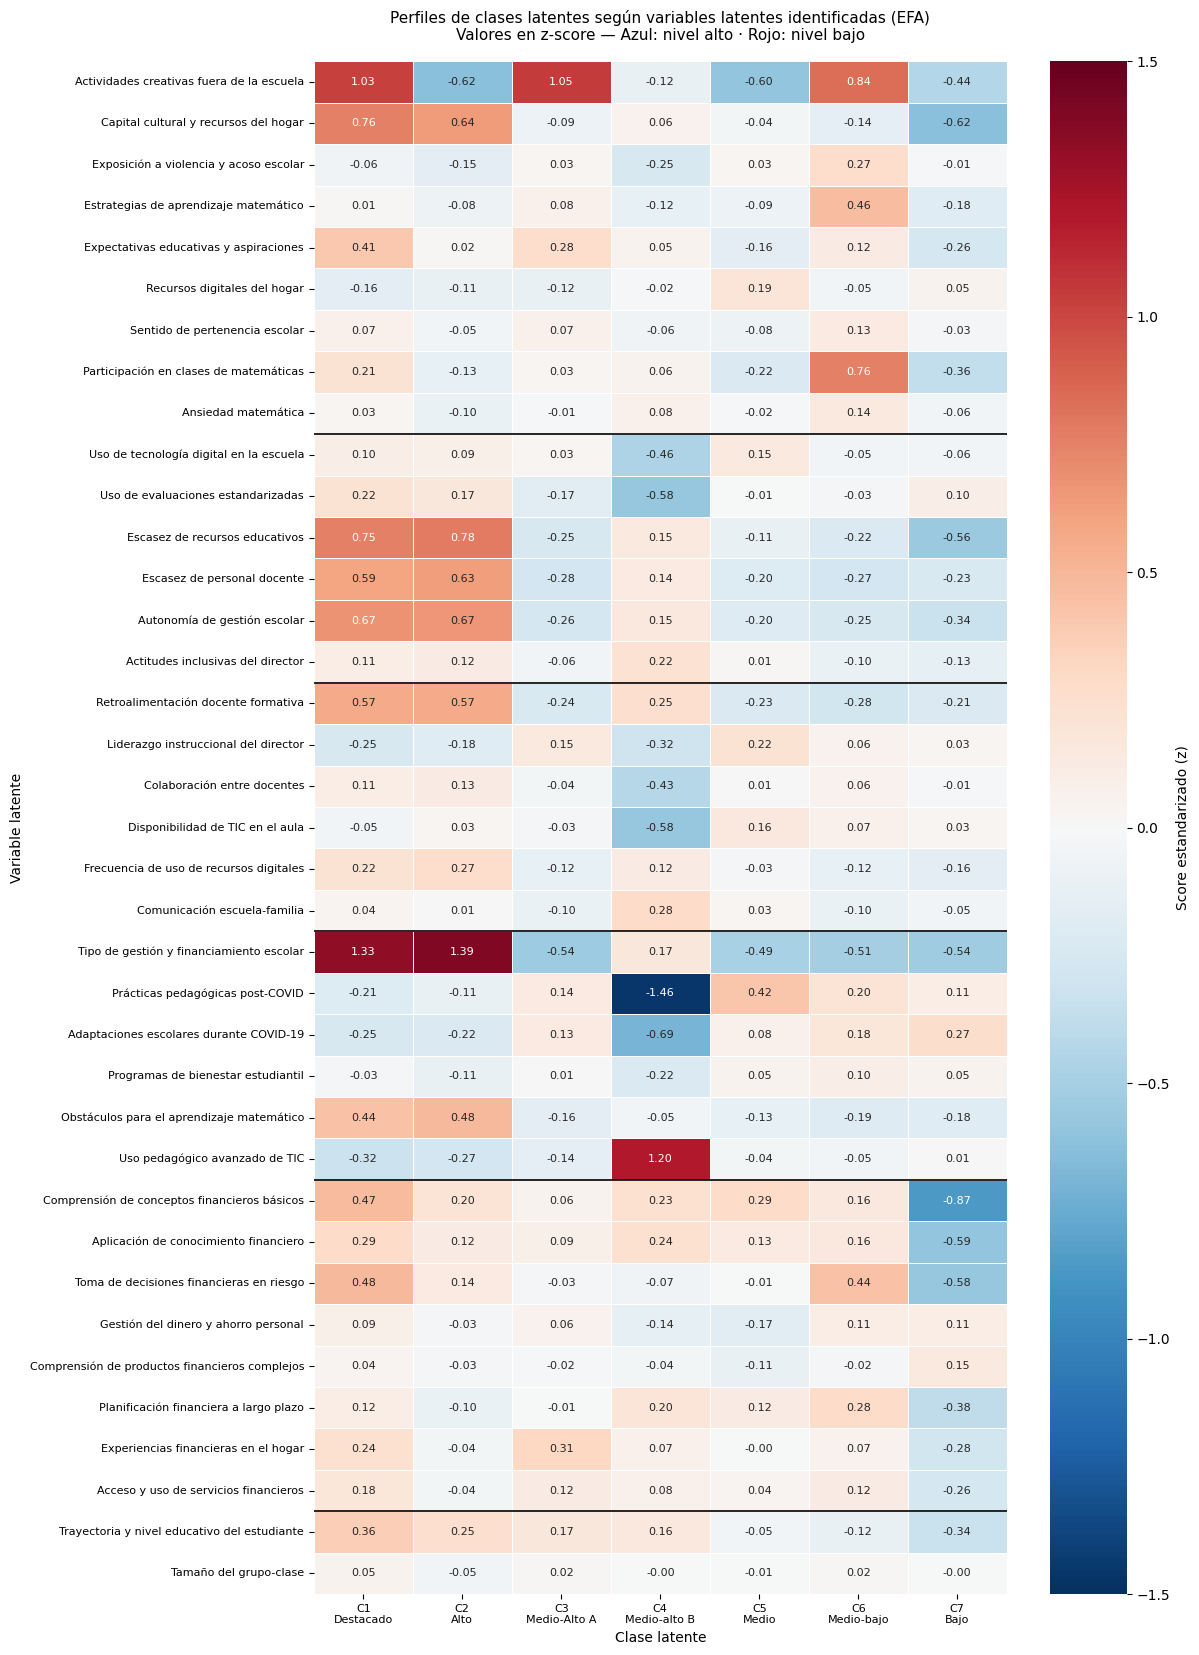

Guardado: figura_perfiles_clases_latentes.png


In [ ]:
# Transponer para que factores sean filas y clases columnas
df_plot = df_perfil_named.T

# Abreviar nombres de clases para el gráfico
df_plot.columns = [
    "C1\nDestacado", "C2\nAlto", "C3\nMedio-Alto A",
    "C4\nMedio-alto B", "C5\nMedio", "C6\nMedio-bajo", "C7\nBajo"
]

altura = max(10, len(df_plot) * 0.45)
fig, ax = plt.subplots(figsize=(12, altura))

sns.heatmap(
    df_plot,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1.5,
    vmax=1.5,
    linewidths=0.4,
    linecolor="white",
    ax=ax,
    annot_kws={"size": 8},
    cbar_kws={"label": "Score estandarizado (z)"},
)

ax.set_title(
    "Perfiles de clases latentes según variables latentes identificadas (EFA)\n"
    "Valores en z-score — Azul: nivel alto · Rojo: nivel bajo",
    fontsize=11, pad=15
)
ax.set_xlabel("Clase latente", fontsize=10)
ax.set_ylabel("Variable latente", fontsize=10)
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=8)

# Separadores visuales por bloque
bloques = {
    "Estudiante": len([f for f in factores_cols if "estudiante" in f]),
    "Escuela A" : len([f for f in factores_cols if "escuela_a" in f]),
    "Escuela B" : len([f for f in factores_cols if "escuela_b" in f]),
    "Escuela C" : len([f for f in factores_cols if "escuela_c" in f]),
    "Finanzas"  : len([f for f in factores_cols if "finanzas" in f]),
    "Otros"     : len([f for f in factores_cols if "otros" in f]),
}
pos = 0
for nombre_bloque, n in bloques.items():
    if n > 0 and pos > 0:
        ax.axhline(pos, color="black", linewidth=1.2)
    pos += n

plt.tight_layout()
plt.savefig("/workspace/data/img_report/figura_perfiles_clases_latentes.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardado: figura_perfiles_clases_latentes.png")

## 5. Variables latentes más discriminantes entre clases

Identificar qué factores tienen mayor varianza entre clases — los más importantes para explicar el rendimiento.

In [8]:
from scipy import stats

resultados_anova = []

for factor in factores_cols:
    grupos = [
        df_scores_z[df_scores_z["clase_lca"] == k][factor].dropna()
        for k in sorted(df_scores_z["clase_lca"].unique())
    ]
    try:
        f_stat, p_val = stats.f_oneway(*grupos)
        # Eta-cuadrado como medida de tamaño del efecto
        medias = [g.mean() for g in grupos]
        rango  = max(medias) - min(medias)
        resultados_anova.append({
            "factor"        : factor,
            "nombre"        : NOMBRES_FACTORES.get(factor, factor),
            "F"             : round(f_stat, 2),
            "p_valor"       : round(p_val, 4),
            "rango_medias"  : round(rango, 3),
        })
    except:
        pass

df_anova = pd.DataFrame(resultados_anova).sort_values("F", ascending=False)

print("Top 15 variables latentes más discriminantes entre clases (ANOVA):")
print("═" * 75)
print(f"  {'Variable latente':<45} {'F':>8} {'p':>8} {'Rango':>8}")
print("═" * 75)
for _, fila in df_anova.head(15).iterrows():
    sig = "***" if fila["p_valor"] < 0.001 else "**" if fila["p_valor"] < 0.01 else "*"
    print(f"  {fila['nombre'][:44]:<45} {fila['F']:>8.1f} {sig:>8} {fila['rango_medias']:>8.3f}")
print("═" * 75)
print("*** p<0.001  ** p<0.01  * p<0.05")

Top 15 variables latentes más discriminantes entre clases (ANOVA):
═══════════════════════════════════════════════════════════════════════════
  Variable latente                                     F        p    Rango
═══════════════════════════════════════════════════════════════════════════
  Tipo de gestión y financiamiento escolar        2057.1      ***    1.927
  Actividades creativas fuera de la escuela       1105.3      ***    1.679
  Prácticas pedagógicas post-COVID                 344.2      ***    1.876
  Escasez de recursos educativos                   342.4      ***    1.334
  Comprensión de conceptos financieros básicos     320.5      ***    1.340
  Capital cultural y recursos del hogar            299.1      ***    1.381
  Autonomía de gestión escolar                     220.6      ***    1.009
  Uso pedagógico avanzado de TIC                   191.2      ***    1.517
  Participación en clases de matemáticas           180.4      ***    1.122
  Escasez de personal docente  

In [13]:
# Ver tabla de perfiles en números
print("\nTabla de perfiles por clase (z-scores):")
print(df_perfil_named.round(2).to_string())


Tabla de perfiles por clase (z-scores):
                                    Actividades creativas fuera de la escuela  Capital cultural y recursos del hogar  Exposición a violencia y acoso escolar  Estrategias de aprendizaje matemático  Expectativas educativas y aspiraciones  Recursos digitales del hogar  Sentido de pertenencia escolar  Participación en clases de matemáticas  Ansiedad matemática  Uso de tecnología digital en la escuela  Uso de evaluaciones estandarizadas  Escasez de recursos educativos  Escasez de personal docente  Autonomía de gestión escolar  Actitudes inclusivas del director  Retroalimentación docente formativa  Liderazgo instruccional del director  Colaboración entre docentes  Disponibilidad de TIC en el aula  Frecuencia de uso de recursos digitales  Comunicación escuela-familia  Tipo de gestión y financiamiento escolar  Prácticas pedagógicas post-COVID  Adaptaciones escolares durante COVID-19  Programas de bienestar estudiantil  Obstáculos para el aprendizaje mat

## 6. Enriquecer con variables de contexto

In [10]:
mapa_comunidad = {
    "A village, hamlet or rural area (fewer than 3 000 people)" : "Rural",
    "A small town (3 000 to about 15 000 people)"               : "Pueblo pequeño",
    "A town (15 000 to about 100 000 people)"                   : "Ciudad pequeña",
    "A city (100 000 to about 1 000 000 people)"                : "Ciudad",
    "A large city (1 000 000 to about 10 000 000 people)"       : "Ciudad grande",
    "A megacity (with over 10 000 000 people)"                  : "Megaciudad",
}

df_lca["tipo_comunidad"] = df_raw["SC001Q01TA"].map(mapa_comunidad).values
df_lca["tipo_escuela"]   = df_raw["SC013Q01TA"].apply(
    lambda x: "Pública" if isinstance(x, str) and "public" in x.lower() else "Privada"
).values
df_lca["estrato"]        = df_raw["STRATUM"].values

# Reordenar clases por rendimiento
df_lca["clase_label"] = df_lca["clase_lca"].map(etiquetas_clase)

# Tabla comunidad × clase
tabla_comunidad = pd.crosstab(
    df_lca["clase_label"],
    df_lca["tipo_comunidad"],
    normalize="index"
).round(3) * 100
tabla_comunidad = tabla_comunidad.loc[list(etiquetas_clase.values())]

print("Distribución de tipo de comunidad por clase latente (%):")
print(tabla_comunidad.to_string())

# Tabla escuela × clase
tabla_escuela = pd.crosstab(
    df_lca["clase_label"],
    df_lca["tipo_escuela"],
    normalize="index"
).round(3) * 100
tabla_escuela = tabla_escuela.loc[list(etiquetas_clase.values())]

print("\nDistribución de tipo de escuela por clase latente (%):")
print(tabla_escuela.to_string())

Distribución de tipo de comunidad por clase latente (%):
tipo_comunidad                      Ciudad  Ciudad grande  Ciudad pequeña  Megaciudad  Pueblo pequeño  Rural
clase_label                                                                                                 
Clase 1 — Rendimiento destacado       16.7            3.7            29.8         2.5            30.8   16.5
Clase 2 — Rendimiento alto             5.8            2.3            16.7         3.1            24.5   47.7
Clase 3 — Rendimiento medio-alto A    14.6            0.0            25.4         3.0            29.8   27.2
Clase 4 — Rendimiento medio-alto B    34.4            2.7            21.0         3.3            22.4   16.2
Clase 5 — Rendimiento medio           33.3            2.8            24.9         1.5            20.3   17.2
Clase 6 — Rendimiento medio-bajo      14.4            2.2            30.1         3.4            31.0   19.0
Clase 7 — Rendimiento bajo             9.8            2.6            25

## 7. Gráfico de contexto por clase

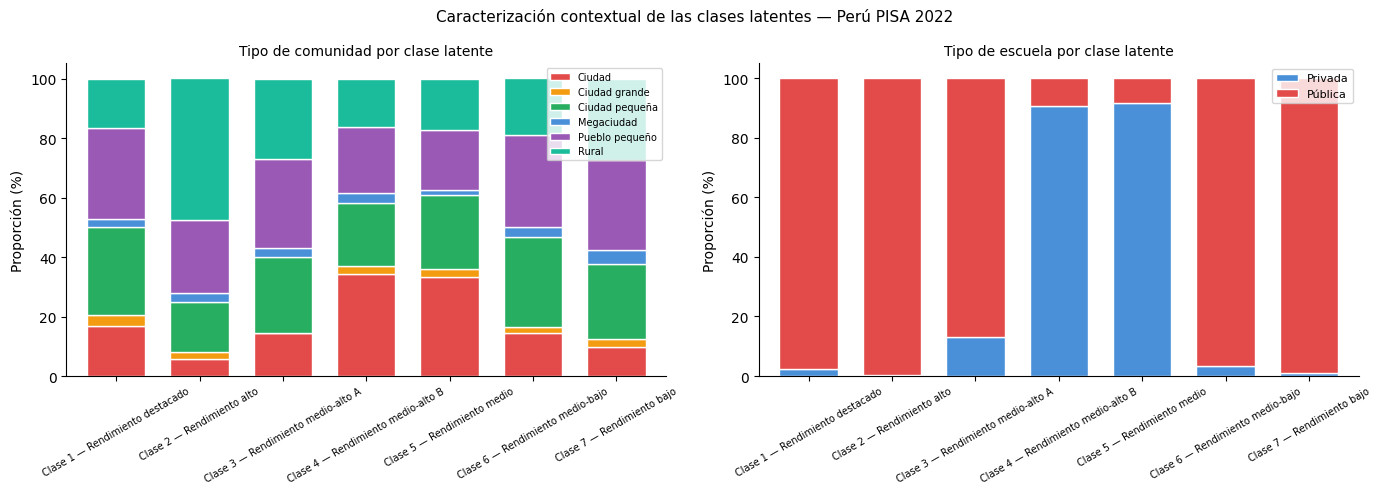

Guardado: figura_contexto_clases.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores_comunidad = ["#E24B4A", "#F39C12", "#27AE60", "#4A90D9", "#9B59B6", "#1ABC9C"]

# Gráfico 1 — tipo de comunidad
tabla_comunidad.plot(
    kind="bar", stacked=True, ax=axes[0],
    color=colores_comunidad[:len(tabla_comunidad.columns)],
    edgecolor="white", width=0.7
)
axes[0].set_title("Tipo de comunidad por clase latente", fontsize=10)
axes[0].set_xlabel("")
axes[0].set_ylabel("Proporción (%)")
axes[0].tick_params(axis="x", rotation=30, labelsize=7)
axes[0].legend(fontsize=7, loc="upper right")
axes[0].spines[["top", "right"]].set_visible(False)

# Gráfico 2 — tipo de escuela
tabla_escuela.plot(
    kind="bar", stacked=True, ax=axes[1],
    color=["#4A90D9", "#E24B4A"],
    edgecolor="white", width=0.7
)
axes[1].set_title("Tipo de escuela por clase latente", fontsize=10)
axes[1].set_xlabel("")
axes[1].set_ylabel("Proporción (%)")
axes[1].tick_params(axis="x", rotation=30, labelsize=7)
axes[1].legend(fontsize=8)
axes[1].spines[["top", "right"]].set_visible(False)

plt.suptitle(
    "Caracterización contextual de las clases latentes — Perú PISA 2022",
    fontsize=11
)
plt.tight_layout()
plt.savefig("/workspace/data/img_report/figura_contexto_clases.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardado: figura_contexto_clases.png")

## 8. Guardar tablas para el artículo

In [12]:
# Tabla principal de perfiles
df_perfil_named.T.to_csv("/workspace/data/ouputs/tabla_perfiles_clases.csv")
print("Guardado: tabla_perfiles_clases.csv")

# Tabla de contexto
tabla_comunidad.to_csv("/workspace/data/ouputs/tabla_contexto_comunidad.csv")
tabla_escuela.to_csv("/workspace/data/ouputs/tabla_contexto_escuela.csv")
print("Guardado: tabla_contexto_comunidad.csv")
print("Guardado: tabla_contexto_escuela.csv")

# Ranking de variables latentes discriminantes
df_anova.to_csv("/workspace/data/ouputs/tabla_anova_factores.csv", index=False)
print("Guardado: tabla_anova_factores.csv")

print("\n✓ Paso 6 completado.")
print("Siguiente paso: redactar sección de resultados del artículo en inglés.")

Guardado: tabla_perfiles_clases.csv
Guardado: tabla_contexto_comunidad.csv
Guardado: tabla_contexto_escuela.csv
Guardado: tabla_anova_factores.csv

✓ Paso 6 completado.
Siguiente paso: redactar sección de resultados del artículo en inglés.
